In [103]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Agenda 

    Need a clearity on who is spending more money for shopping incase of gender, age_group, state, occuptaion, Product_category,marital_status

In [104]:
df=pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\Qspider\datasets\Data-Analysis-Datasets\Datasets-Practice\sales_data.csv",encoding="ISO-8859-1")
df

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11246,1000695,Manning,P00296942,M,18-25,19,1,Maharashtra,Western,Chemical,Office,4,370.0,NaN,NaN
11247,1004089,Reichenbach,P00171342,M,26-35,33,0,Haryana,Northern,Healthcare,Veterinary,3,367.0,NaN,NaN
11248,1001209,Oshin,P00201342,F,36-45,40,0,Madhya Pradesh,Central,Textile,Office,4,213.0,NaN,NaN
11249,1004023,Noonan,P00059442,M,36-45,37,0,Karnataka,Southern,Agriculture,Office,3,206.0,NaN,NaN


In [105]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  str    
 2   Product_ID        11251 non-null  str    
 3   Gender            11251 non-null  str    
 4   Age Group         11251 non-null  str    
 5   Age               11251 non-null  int64  
 6   Marital_Status    11251 non-null  int64  
 7   State             11251 non-null  str    
 8   Zone              11251 non-null  str    
 9   Occupation        11251 non-null  str    
 10  Product_Category  11251 non-null  str    
 11  Orders            11251 non-null  int64  
 12  Amount            11239 non-null  float64
 13  Status            0 non-null      float64
 14  unnamed1          0 non-null      float64
dtypes: float64(3), int64(4), str(8)
memory usage: 1.3 MB


In [106]:
df.describe(include="all")

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
count,1.125100e+04,11251,11251,11251,11251,11251.000000,11251.000000,11251,11251,11251,11251,11251.000000,11239.000000,0.0,0.0
unique,NaN,1250,2351,2,7,NaN,NaN,16,5,15,18,NaN,NaN,NaN,NaN
top,NaN,Vishakha,P00265242,F,26-35,NaN,NaN,Uttar Pradesh,Central,IT Sector,Clothing & Apparel,NaN,NaN,NaN,NaN
freq,NaN,42,53,7842,4543,NaN,NaN,1946,4296,1588,2655,NaN,NaN,NaN,NaN
mean,1.003004e+06,NaN,NaN,NaN,NaN,35.421207,0.420318,NaN,NaN,NaN,NaN,2.489290,9453.610858,NaN,NaN
std,1.716125e+03,NaN,NaN,NaN,NaN,12.754122,0.493632,NaN,NaN,NaN,NaN,1.115047,5222.355869,NaN,NaN
min,1.000001e+06,NaN,NaN,NaN,NaN,12.000000,0.000000,NaN,NaN,NaN,NaN,1.000000,188.000000,NaN,NaN
25%,1.001492e+06,NaN,NaN,NaN,NaN,27.000000,0.000000,NaN,NaN,NaN,NaN,1.500000,5443.000000,NaN,NaN
50%,1.003065e+06,NaN,NaN,NaN,NaN,33.000000,0.000000,NaN,NaN,NaN,NaN,2.000000,8109.000000,NaN,NaN
75%,1.004430e+06,NaN,NaN,NaN,NaN,43.000000,1.000000,NaN,NaN,NaN,NaN,3.000000,12675.000000,NaN,NaN


In [107]:
# How many null values present in each column 
df.isnull().sum()

User_ID                 0
Cust_name               0
Product_ID              0
Gender                  0
Age Group               0
Age                     0
Marital_Status          0
State                   0
Zone                    0
Occupation              0
Product_Category        0
Orders                  0
Amount                 12
Status              11251
unnamed1            11251
dtype: int64

In [108]:
# Remove the unwanted column and status from the dataset.
df.drop("unnamed1",axis=1,inplace=True)

df.drop("Status",axis=1,inplace=True)

In [109]:
# Now we handle the null values in amount column 
df["Amount"]=df["Amount"].fillna(0)

In [110]:
# df.head()
z={
    "Age Group":"Age_group"
}

df.rename(columns=z,inplace=True)

In [111]:
# In Gender column , we convert F into Female and M into Male

d={
    "F":"Female",
    "M":"Male"
}

df["Gender"]=df["Gender"].map(d)

In [112]:
# In Marital Status column converted into single and married data.

df["Marital_Status"]=df["Marital_Status"].astype(str)

e={
    "0":"Single",
    "1":"Married"
}
df["Marital_Status"]=df["Marital_Status"].map(e)

In [113]:
# Remove duplicates from the datasets.
df.drop_duplicates(inplace=True)

# Plotting 

In [114]:
def labels(lab):
    for i in lab.containers:
        lab.bar_label(i)

([<matplotlib.patches.Wedge at 0x1c9d7ebfc50>,
 [Text(-0.6461032236262746, 0.8902531237910578, 'Female'),
  Text(0.7048401967718487, -0.9711849962878452, 'Male')],
 [Text(-0.3524199401597861, 0.48559261297694056, '70%'),
  Text(0.4111567814502451, -0.5665245811679096, '30%')])

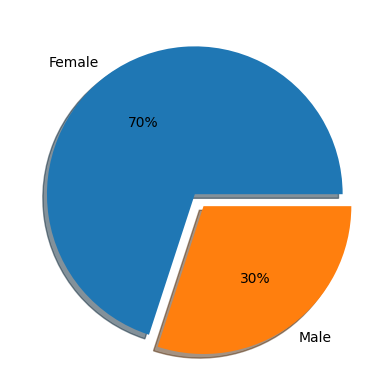

In [115]:
# Need a clearity on who is spending more money for shopping incase of gender, age_group, state, occuptaion, Product_category,marital_status.

"""Spending of Each Gender"""
fe=df[df["Gender"]=="Female"]["Amount"].sum()
me=df[df["Gender"]=="Male"]["Amount"].sum()
l=[fe,me]
plt.pie(l,labels=["Female","Male"],autopct="%0.0f%%",shadow=True,explode=(0,0.1))

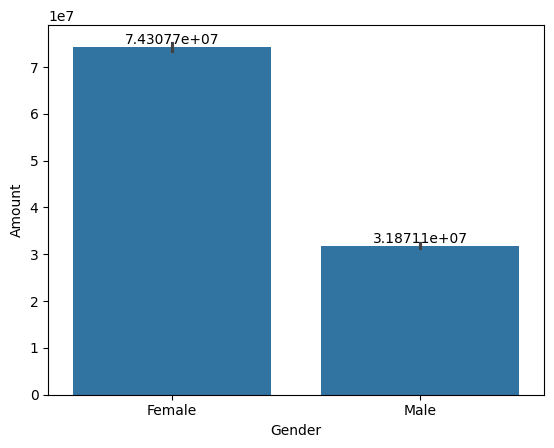

In [120]:
a=sns.barplot(x="Gender",y="Amount",data=df,estimator=sum)
labels(a)


<Axes: ylabel='Count'>

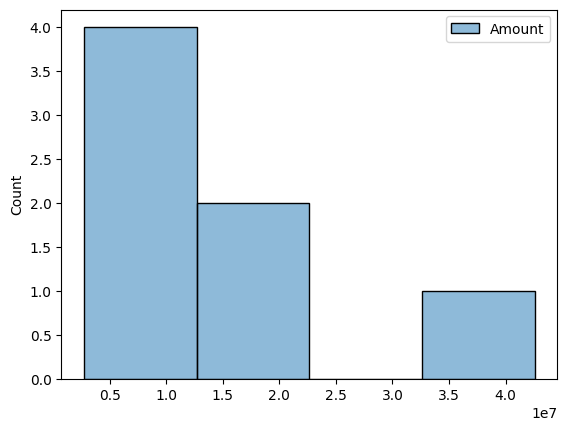

In [ ]:
"""Spending of Each age_group"""
ag=df.groupby("Age_group")["Amount"].sum()

In [ ]:
"""Spending of Each Gender"""
# df.pivot_table(
#     values=["Gender","Age_group" ,"State", "Occupation", "Product_Category","Marital_Status"],
#     index="Amounts",
#     aggfunc=["sum"]
)

KeyError: 'Amounts'

In [ ]:
df

,User_ID,Cust_name,Product_ID,Gender,Age_group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,Female,26-35,28,Single,Maharashtra,Western,Healthcare,Auto,1,23952.0
1,1000732,Kartik,P00110942,Female,26-35,35,Married,Andhra Pradesh,Southern,Govt,Auto,3,23934.0
2,1001990,Bindu,P00118542,Female,26-35,35,Married,Uttar Pradesh,Central,Automobile,Auto,3,23924.0
3,1001425,Sudevi,P00237842,Male,0-17,16,Single,Karnataka,Southern,Construction,Auto,2,23912.0
4,1000588,Joni,P00057942,Male,26-35,28,Married,Gujarat,Western,Food Processing,Auto,2,23877.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11246,1000695,Manning,P00296942,Male,18-25,19,Married,Maharashtra,Western,Chemical,Office,4,370.0
11247,1004089,Reichenbach,P00171342,Male,26-35,33,Single,Haryana,Northern,Healthcare,Veterinary,3,367.0
11248,1001209,Oshin,P00201342,Female,36-45,40,Single,Madhya Pradesh,Central,Textile,Office,4,213.0
11249,1004023,Noonan,P00059442,Male,36-45,37,Single,Karnataka,Southern,Agriculture,Office,3,206.0
